In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

warnings.filterwarnings("ignore")
%matplotlib inline
plt.style.use("seaborn-v0_8-darkgrid")

# ── EDIT THESE ────────────────────────────────────────────────
START  = "2022-01-01"
END    = "2024-12-31"
WINDOW = 60           # rolling window in trading days

TICKERS = {
    "PSRHF":   "Pulsar Helium (OTC)",
    "HLOGF":   "Helium One Global (OTC)",
    "HELI.NE": "First Helium (NEO)",
    "HEVI.V":  "Helium Evolution (TSX-V)",
    "MSGE":    "MSG Entertainment (NYSE)",
    "MSGS":    "MSG Sports (NYSE)",
}
# ─────────────────────────────────────────────────────────────

OUTPUT_DIR = "pairwise_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Config: {START} → {END}  |  window={WINDOW}d  |  {len(TICKERS)} tickers")


Config: 2022-01-01 → 2024-12-31  |  window=60d  |  6 tickers


In [3]:
def download_prices(tickers, start, end):
    frames = {}
    for ticker in tickers:
        print(f"  Fetching {ticker} ...", end=" ")
        try:
            raw   = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
            close = raw["Close"].squeeze().dropna()
            if len(close) < 10:
                print(f"⚠  only {len(close)} rows — skipped"); continue
            frames[ticker] = close
            print(f"✓  {len(close)} rows")
        except Exception as e:
            print(f"✗  {e}")
    return pd.DataFrame(frames)

prices = download_prices(list(TICKERS.keys()), START, END)
prices.tail()


  Fetching PSRHF ... ✓  270 rows
  Fetching HLOGF ... ✓  752 rows
  Fetching HELI.NE ... 


1 Failed download:
['HELI.NE']: YFPricesMissingError('possibly delisted; no price data found  (1d 2022-01-01 -> 2024-12-31)')


⚠  only 0 rows — skipped
  Fetching HEVI.V ... ✓  691 rows
  Fetching MSGE ... ✓  430 rows
  Fetching MSGS ... ✓  752 rows


,PSRHF,HLOGF,HEVI.V,MSGE,MSGS
Date,,,,,
2024-12-23,0.46000,0.0141,0.105,33.060001,220.309998
2024-12-24,0.48510,0.0141,0.110,33.200001,221.190002
2024-12-26,0.51950,0.0141,NaN,33.450001,221.720001
2024-12-27,0.48775,0.0140,0.105,33.250000,221.100006
2024-12-30,0.51720,0.0146,0.110,35.830002,228.070007


In [5]:
def log_returns(prices):
    return np.log(prices / prices.shift(1)).dropna()

def align_returns(rets):
    return rets.dropna(axis=0, how="any")

rets = align_returns(log_returns(prices))
print(f"Overlapping trading days: {len(rets)}")
rets.describe().round(5)


Overlapping trading days: 252


,PSRHF,HLOGF,HEVI.V,MSGE,MSGS
count,252.00000,252.00000,252.00000,252.00000,252.00000
mean,0.00470,-0.00219,-0.00126,0.00029,0.00069
std,0.08521,0.22414,0.07021,0.01840,0.01077
min,-0.38052,-0.88022,-0.17589,-0.09566,-0.02590
25%,-0.03922,-0.09720,-0.04497,-0.00901,-0.00546
50%,0.00076,0.00000,0.00000,0.00049,0.00093
75%,0.04137,0.06072,0.04303,0.00968,0.00640
max,0.47446,0.79113,0.21256,0.07473,0.05848


In [7]:
def mean_pairwise_correlation(corr):
    n = len(corr)
    vals = [corr.iloc[i, j] for i in range(n) for j in range(i+1, n)]
    return float(np.mean(vals)) if vals else np.nan

corr      = rets.corr(method="pearson")
mean_corr = mean_pairwise_correlation(corr)

n = len(corr.columns)
max_v, min_v = -99.0, 99.0
max_pair, min_pair = ("",""), ("","")
for i in range(n):
    for j in range(i+1, n):
        v = corr.iloc[i, j]
        if v > max_v: max_v, max_pair = v, (corr.columns[i], corr.columns[j])
        if v < min_v: min_v, min_pair = v, (corr.columns[i], corr.columns[j])

print(f"Mean pairwise correlation : {mean_corr:+.4f}")
print(f"Strongest pair            : {max_pair[0]} / {max_pair[1]}  ({max_v:+.4f})")
print(f"Weakest pair              : {min_pair[0]} / {min_pair[1]}  ({min_v:+.4f})")
if   mean_corr > 0.6: print("⚡ HIGH — little diversification benefit")
elif mean_corr > 0.3: print("➡  MODERATE — some diversification")
else:                  print("✓  LOW — largely uncorrelated; good diversification")

corr.round(3)


Mean pairwise correlation : +0.0676
Strongest pair            : MSGE / MSGS  (+0.4203)
Weakest pair              : HEVI.V / MSGS  (-0.1049)
✓  LOW — largely uncorrelated; good diversification


,PSRHF,HLOGF,HEVI.V,MSGE,MSGS
PSRHF,1.000,0.057,0.112,0.040,0.057
HLOGF,0.057,1.000,0.007,0.027,0.041
HEVI.V,0.112,0.007,1.000,0.020,-0.105
MSGE,0.040,0.027,0.020,1.000,0.420
MSGS,0.057,0.041,-0.105,0.420,1.000


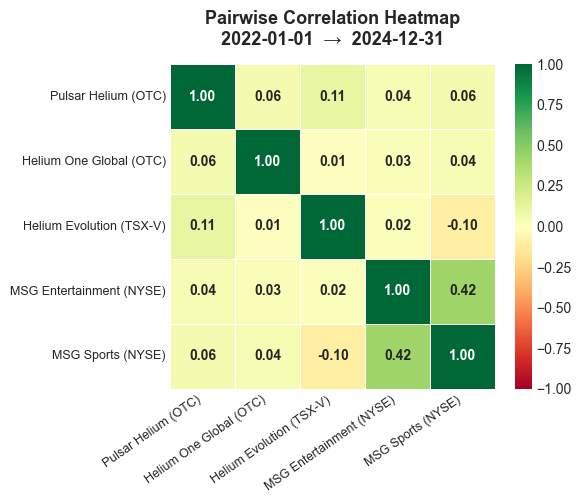

In [8]:
fig, ax = plt.subplots(figsize=(max(6, len(corr)*1.1), max(5, len(corr))))
nice_labels = [TICKERS.get(t, t) for t in corr.columns]

sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdYlGn",
    vmin=-1, vmax=1, center=0,
    linewidths=0.5, linecolor="white",
    ax=ax, square=True,
    annot_kws={"size": 10, "weight": "bold"},
    xticklabels=nice_labels, yticklabels=nice_labels,
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
ax.set_title(f"Pairwise Correlation Heatmap\n{START}  →  {END}",
             fontsize=13, fontweight="bold", pad=14)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/fig1_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


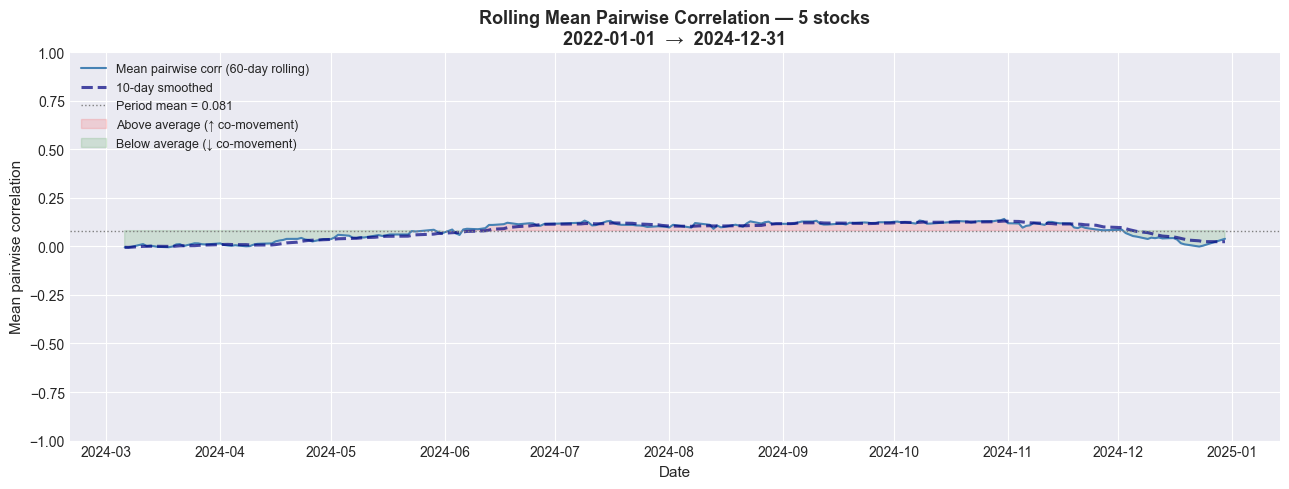

Range: [-0.005, 0.141]  |  Period-end: 0.039


In [9]:
def rolling_mean_pairwise(rets, window=60):
    results, dates = [], []
    for end_i in range(window, len(rets)+1):
        w    = rets.iloc[end_i-window : end_i]
        corr = w.corr(method="pearson")
        results.append(mean_pairwise_correlation(corr))
        dates.append(rets.index[end_i-1])
    return pd.Series(results, index=dates, name="mean_pairwise_corr")

if len(rets) >= WINDOW:
    rolling = rolling_mean_pairwise(rets, window=WINDOW)
    smooth  = rolling.rolling(10, min_periods=1).mean()

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(rolling.index, rolling.values, color="steelblue", lw=1.5,
            label=f"Mean pairwise corr ({WINDOW}-day rolling)")
    ax.plot(smooth.index, smooth.values, color="navy", lw=2.2,
            linestyle="--", alpha=0.7, label="10-day smoothed")

    period_mean = rolling.mean()
    ax.axhline(period_mean, color="gray", lw=1, linestyle=":",
               label=f"Period mean = {period_mean:.3f}")
    ax.fill_between(rolling.index, rolling.values, period_mean,
                    where=(rolling.values > period_mean),
                    alpha=0.12, color="red",   label="Above average (↑ co-movement)")
    ax.fill_between(rolling.index, rolling.values, period_mean,
                    where=(rolling.values < period_mean),
                    alpha=0.12, color="green", label="Below average (↓ co-movement)")

    ax.set_title(f"Rolling Mean Pairwise Correlation — {len(rets.columns)} stocks\n{START}  →  {END}",
                 fontsize=13, fontweight="bold")
    ax.set_ylabel("Mean pairwise correlation", fontsize=11)
    ax.set_xlabel("Date", fontsize=11)
    ax.legend(fontsize=9, loc="upper left")
    ax.set_ylim(-1, 1)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/fig2_rolling_correlation.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Range: [{rolling.min():.3f}, {rolling.max():.3f}]  |  Period-end: {rolling.iloc[-1]:.3f}")
else:
    print(f"⚠  Not enough data for a {WINDOW}-day window. Reduce WINDOW or widen date range.")


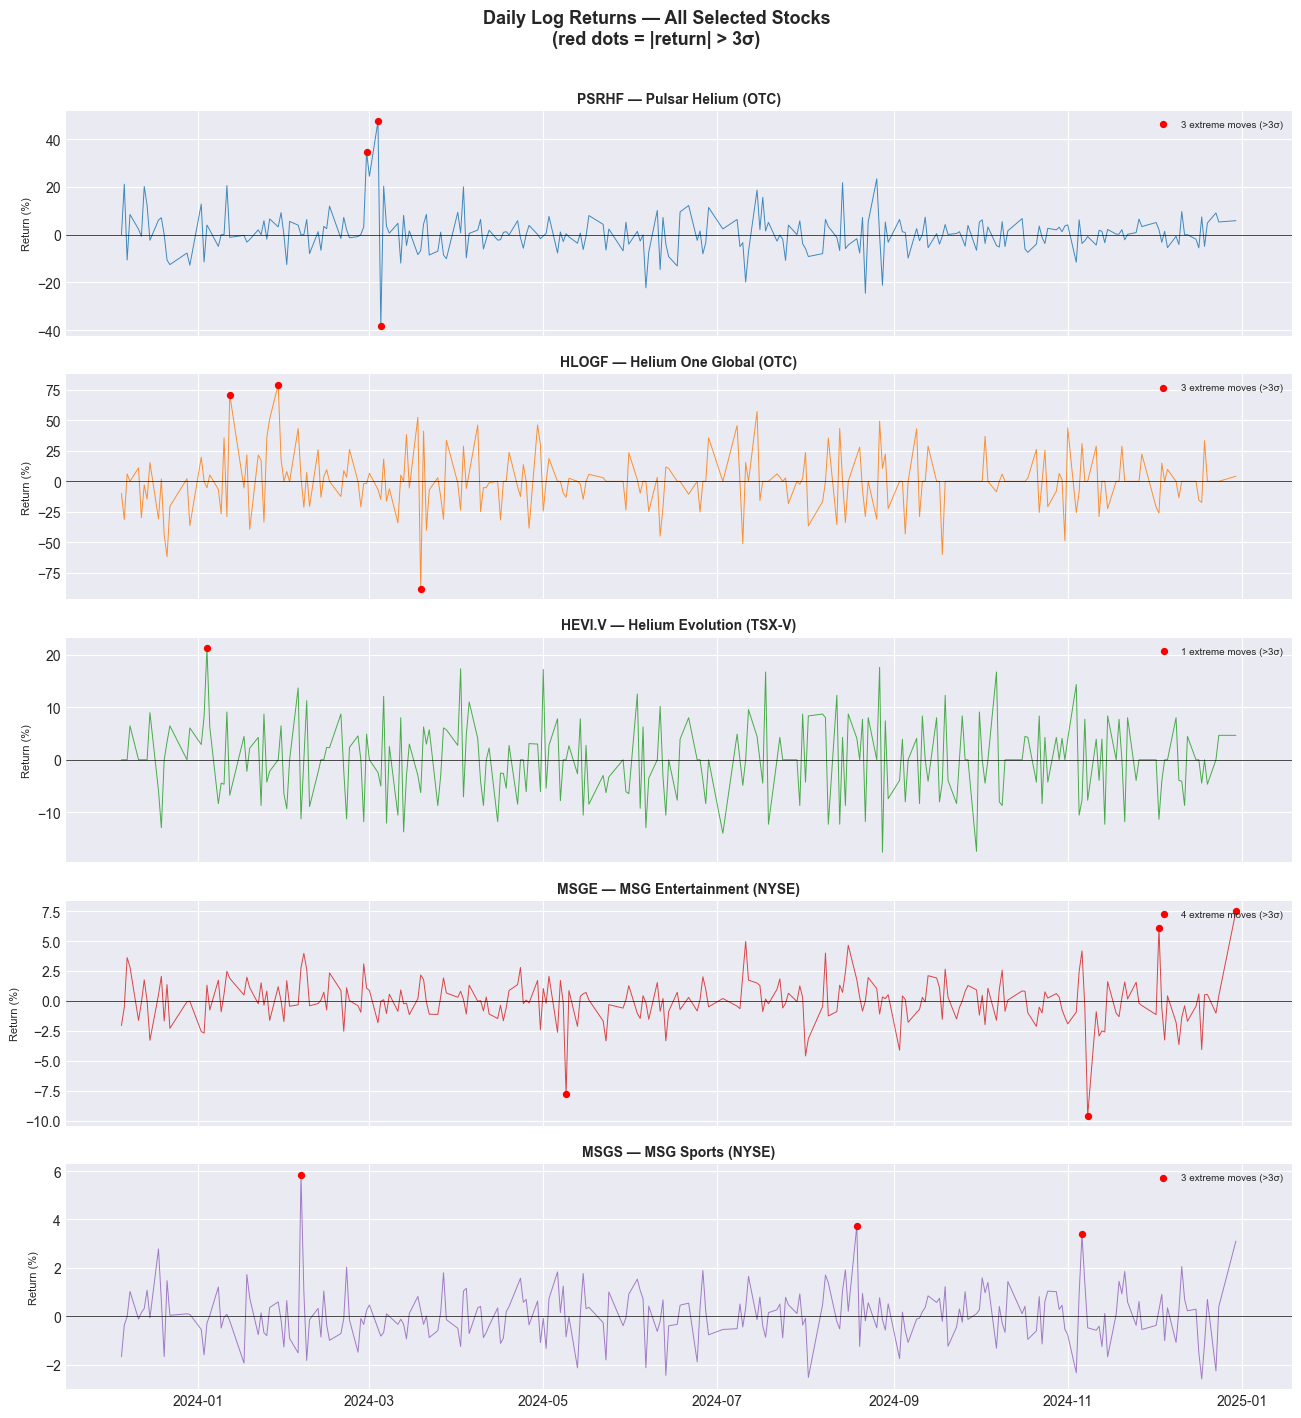

In [10]:
n_t   = len(rets.columns)
fig, axes = plt.subplots(n_t, 1, figsize=(13, 2.8*n_t), sharex=True)
if n_t == 1: axes = [axes]

colors = plt.cm.tab10.colors
for ax, ticker, color in zip(axes, rets.columns, colors):
    series    = rets[ticker] * 100
    threshold = series.std() * 3
    extremes  = series[series.abs() > threshold]
    ax.plot(series.index, series.values, color=color, lw=0.7, alpha=0.85)
    ax.axhline(0, color="black", lw=0.5)
    ax.scatter(extremes.index, extremes.values, color="red", s=18, zorder=5,
               label=f"{len(extremes)} extreme moves (>3σ)")
    ax.set_title(f"{ticker} — {TICKERS.get(ticker, ticker)}", fontsize=10, fontweight="bold")
    ax.set_ylabel("Return (%)", fontsize=8)
    ax.legend(fontsize=7, loc="upper right")

fig.suptitle("Daily Log Returns — All Selected Stocks\n(red dots = |return| > 3σ)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/fig3_return_series.png", dpi=150, bbox_inches="tight")
plt.show()


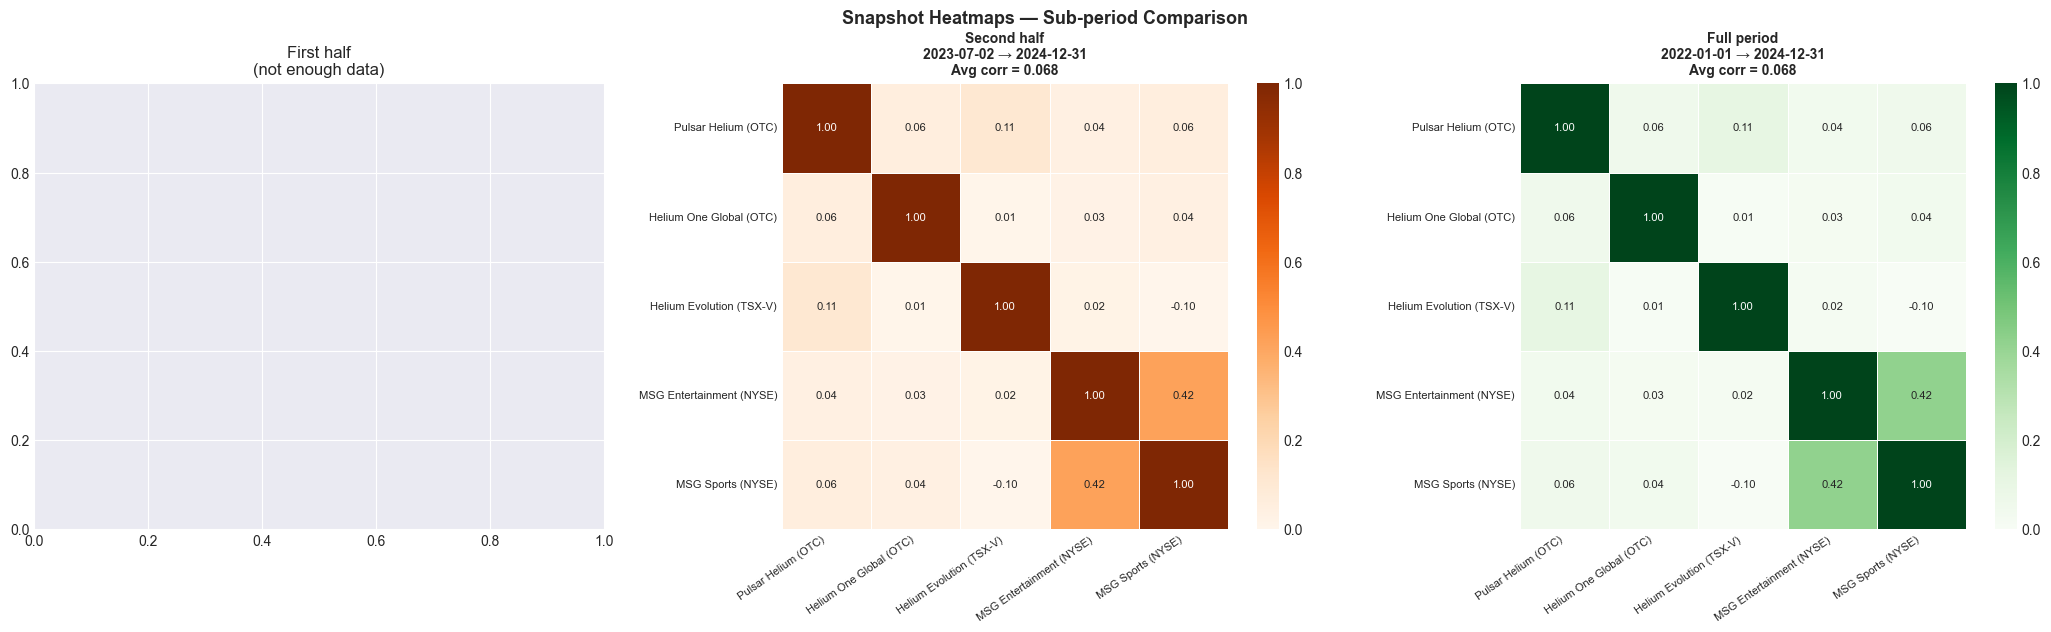

In [11]:
SNAPSHOTS = [
    ("First half",  START,        str(pd.Timestamp(START) + (pd.Timestamp(END)-pd.Timestamp(START))//2)[:10]),
    ("Second half", str(pd.Timestamp(START) + (pd.Timestamp(END)-pd.Timestamp(START))//2)[:10], END),
    ("Full period", START,        END),
]

fig, axes = plt.subplots(1, len(SNAPSHOTS), figsize=(7*len(SNAPSHOTS), 6))
if len(SNAPSHOTS) == 1: axes = [axes]

cmaps = ["Blues", "Oranges", "Greens"]
for ax, (label, s, e), cmap in zip(axes, SNAPSHOTS, cmaps):
    window_rets = align_returns(log_returns(prices[s:e]))
    if len(window_rets) < 5:
        ax.set_title(f"{label}\n(not enough data)"); continue
    c    = window_rets.corr()
    avg  = mean_pairwise_correlation(c)
    nice = [TICKERS.get(t, t) for t in c.columns]
    sns.heatmap(c, annot=True, fmt=".2f", cmap=cmap, vmin=0, vmax=1,
                linewidths=0.5, linecolor="white", ax=ax, square=True,
                annot_kws={"size": 8}, xticklabels=nice, yticklabels=nice)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.set_title(f"{label}\n{s} → {e}\nAvg corr = {avg:.3f}", fontsize=10, fontweight="bold")

fig.suptitle("Snapshot Heatmaps — Sub-period Comparison", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/fig4_snapshot_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()


In [13]:
"""
MF-DFA on Log-Returns | MF-DMA variants on Log-Prices
=======================================================================
Correct input series per method:
  - MF-DFA  → Log-Returns  (stationary, no trend contamination)
  - MF-BDMA → Log-Prices   (DMA designed for price-level series with trend)
  - MF-CDMA → Log-Prices
  - MF-FDMA → Log-Prices

DMA operates directly on log-prices (no integration step needed since
log-prices already have the slow-moving trend the moving average tracks).

DFA integrates returns first (standard DFA profile construction).

6-panel layout:
  (a) raw series         (b) F_q(s) log-log     (c) H(q)
  (d) tau(q)             (e) alpha(q)            (f) f(alpha) spectrum
"""

import numpy as np
import yfinance as yf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.signal import savgol_filter
import os, warnings

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# PARAMETERS
# ─────────────────────────────────────────────────────────────────────────────
# Line ~20 — replace the entire TICKERS list:
TICKERS = [
    "PSRHF",
    "HLOGF",
    "HELI.NE",
    "HEVI.V",
    "MSGE",
    "MSGS",
]
START     = "2010-01-01"
END       = "2026-04-11"

Q_VALS    = np.arange(-30, 31, 5, dtype=float)
SCALE_MIN = 20
N_SCALES  = 30
POLY_ORD  = 1
SCALE_MAX = 800
OVERLAP   = 0.75

OUT_DIR   = "he_msg_exp"
os.makedirs(OUT_DIR, exist_ok=True)

PAPER_COLORS = [
    "#d62728", "#2ca02c", "#1f77b4", "#000000", "#9467bd",
    "#ff7f0e", "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#7f7f7f",
]

# ─────────────────────────────────────────────────────────────────────────────
# HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def prepare_series(price):
    price     = price[price > 0]
    log_price = np.log(price)
    returns   = np.diff(log_price)
    return price, log_price, returns


def integrate(x):
    """
    DFA profile: Y(i) = sum_{k=1}^{i} [x(k) - mean(x)]
    Converts stationary returns into a random-walk-like profile
    with genuine scale-dependent variance.
    Used only by MF-DFA.
    """
    return np.cumsum(x - x.mean())


def _overlap_starts(N, s, overlap):
    step = max(1, int(s * (1.0 - overlap)))
    return np.arange(0, N - s + 1, step)


# ─────────────────────────────────────────────────────────────────────────────
# MF-DFA  — input: log-returns
# ─────────────────────────────────────────────────────────────────────────────
def mfdfa(x, q_vals, scale_min, scale_max, n_scales, poly_ord=1, overlap=0.75):
    """
    MF-DFA on log-returns:
      1. Integrate returns → profile Y
      2. For each scale s, detrend each overlapping segment with a polynomial
      3. RMS of residuals → local fluctuation F_v(s)
      4. q-th order average over segments → F_q(s)
      5. Slope of log F_q vs log s → H(q)
    """
    y = integrate(x)
    N = len(y)
    scale_max = min(scale_max, N // 4)
    scale_min = max(scale_min, poly_ord + 2)

    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )
    scales = scales[scales >= scale_min]

    Fqs = np.full((len(q_vals), len(scales)), np.nan)

    for i, s in enumerate(scales):
        starts = _overlap_starts(N, s, overlap)
        if len(starts) < 4:
            continue

        t   = np.arange(s)
        rms = []
        for st in starts:
            seg  = y[st : st + s]
            coef = np.polyfit(t, seg, poly_ord)
            r    = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r > 0:
                rms.append(r)

        rms = np.asarray(rms)
        if len(rms) == 0:
            continue

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2)))
            else:
                Fqs[j, i] = (np.mean(rms ** q)) ** (1.0 / q)

    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        row  = Fqs[j]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() >= 4:
            hq[j] = np.polyfit(np.log(scales[mask]), np.log(row[mask]), 1)[0]

    return scales, Fqs, hq


# ─────────────────────────────────────────────────────────────────────────────
# MF-DMA  — input: log-prices
# ─────────────────────────────────────────────────────────────────────────────
def mfdma(x, q_vals, scale_min, scale_max, n_scales, theta=0.5, overlap=0.75):
    """
    MF-DMA on log-prices:
      NO integration step — log-prices already carry the slow trend
      that the moving average will track and subtract.

      1. For each scale s, compute moving average of log-prices
         as the local trend (the MA naturally follows the price trend)
      2. Residual = log-price - moving average = detrended fluctuation
      3. q-th order average of squared residuals → F_q(s)
      4. Slope of log F_q vs log s → H(q)

    theta controls moving average asymmetry:
      0.0 → backward MA  (uses only past values, causal)
      0.5 → centred MA   (symmetric, non-causal)
      1.0 → forward MA   (uses only future values)

    H(q) here will be > 1 due to log-price nonstationarity —
    this is expected and consistent with DMA literature.
    The key output is the SHAPE of H(q) and Δα, not the absolute level.
    """
    N = len(x)
    scale_max = min(scale_max, N // 4)
    scale_min = max(scale_min, 4)

    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )
    scales = scales[scales >= scale_min]

    Fqs = np.full((len(q_vals), len(scales)), np.nan)

    for i, s in enumerate(scales):
        starts = _overlap_starts(N, s, overlap)
        if len(starts) < 4:
            continue

        k_back = int(np.floor((s - 1) * theta))
        k_fwd  = int(np.ceil ((s - 1) * (1.0 - theta)))

        sq_res_all = []
        for st in starts:
            seg_end = st + s
            for k in range(st, seg_end):
                # Moving average window around k, clipped to segment bounds
                w_start = max(st,      k - k_back)
                w_end   = min(seg_end, k + k_fwd + 1)
                window  = x[w_start:w_end]
                if len(window) == 0:
                    continue
                sq_res_all.append((x[k] - window.mean()) ** 2)

        sq_res = np.asarray(sq_res_all)
        sq_res = sq_res[sq_res > 0]
        if len(sq_res) == 0:
            continue

        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(sq_res)))
            else:
                Fqs[j, i] = (np.mean(sq_res ** (q / 2.0))) ** (1.0 / q)

    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        row  = Fqs[j]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() >= 4:
            hq[j] = np.polyfit(np.log(scales[mask]), np.log(row[mask]), 1)[0]

    return scales, Fqs, hq


# ─────────────────────────────────────────────────────────────────────────────
# MULTIFRACTAL SPECTRUM
# ─────────────────────────────────────────────────────────────────────────────
def multifractal_spectrum(q_vals, hq):
    tau_q = q_vals * hq - 1.0
    wl = min(5, len(tau_q) if len(tau_q) % 2 == 1 else len(tau_q) - 1)
    tau_smooth = savgol_filter(tau_q, window_length=wl, polyorder=2) if len(tau_q) >= 5 else tau_q
    alpha   = np.gradient(tau_smooth, q_vals)
    D_alpha = q_vals * alpha - tau_smooth
    return tau_q, alpha, D_alpha


# ─────────────────────────────────────────────────────────────────────────────
# 6-PANEL PLOT
# ─────────────────────────────────────────────────────────────────────────────
SERIES_LABELS = {
    "log_prices": "Log-Prices",
    "returns":    "Log-Returns",
}

def plot_6panel(ticker, method, series_key, raw_series,
                scales, Fqs, hq, q_vals, tau_q, alpha, D_alpha):

    series_label = SERIES_LABELS[series_key]
    valid  = np.isfinite(hq)
    colors = (PAPER_COLORS * 4)[: len(q_vals)]

    fig, axs = plt.subplots(2, 3, figsize=(15, 9))
    '''fig.suptitle(
        f"Multifractal analysis  ·  {ticker}  ·  {series_label}  ·  {method}",
        fontsize=13, fontweight="bold", y=1.01,
    )'''

    # (a) raw series
    ax = axs[0, 0]
    ax.plot(raw_series, color="#c0392b", linewidth=0.65)
    ax.set_xlabel("$t$", fontsize=11)
    ax.set_ylabel("$X(t)$", fontsize=11)
    ax.set_title("(a) Time series", fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4g"))

    # (b) F_q(s) log-log
    ax = axs[0, 1]
    legend_handles = []
    for idx_q, (q, c) in enumerate(zip(q_vals, colors)):
        row  = Fqs[idx_q]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() < 2:
            continue
        h, = ax.loglog(scales[mask], row[mask], "o-",
                       color=c, markersize=3.5, linewidth=1.0)
        legend_handles.append((h, f"$q={int(q)}$"))

    ax.set_xlabel("$s$", fontsize=11)
    ax.set_ylabel("$F_q(s)$", fontsize=11)
    ax.set_title("(b) Fluctuation functions $F_q(s)$", fontsize=11)
    step  = max(1, len(legend_handles) // 8)
    shown = legend_handles[::step]
    ax.legend([h for h, _ in shown], [l for _, l in shown],
              fontsize=7, ncol=1, loc="best",
              handlelength=1.2, handletextpad=0.4)

    # (c) H(q)
    ax = axs[0, 2]
    ax.plot(q_vals[valid], hq[valid], "-", color="#1f4e8c", linewidth=2)
    ax.set_xlabel("$q$", fontsize=11)
    ax.set_ylabel("$H(q)$", fontsize=11)
    ax.set_title("(c) Generalised Hurst exponent $H(q)$", fontsize=11)
    ax.axhline(0.5, color="grey", lw=0.8, ls="--", alpha=0.6, label="H=0.5")
    ax.axhline(1.0, color="blue", lw=0.8, ls=":",  alpha=0.6, label="H=1.0")
    ax.legend(fontsize=7)

    # (d) tau(q)
    ax = axs[1, 0]
    ax.plot(q_vals[valid], tau_q[valid], "-", color="#1f4e8c", linewidth=2)
    ax.set_xlabel("$q$", fontsize=11)
    ax.set_ylabel(r"$\tau(q)$", fontsize=11)
    ax.set_title(r"(d) Scaling exponent $\tau(q)$", fontsize=11)
    ax.axhline(0, color="grey", lw=0.8, ls="--", alpha=0.6)

    # (e) alpha(q)
    ax = axs[1, 1]
    valid_s = np.isfinite(alpha) & np.isfinite(D_alpha)
    ax.plot(q_vals[valid_s], alpha[valid_s], "-", color="#1f4e8c", linewidth=2)
    ax.set_xlabel("$q$", fontsize=11)
    ax.set_ylabel(r"$\alpha(q)$", fontsize=11)
    ax.set_title(r"(e) Singularity strength $\alpha(q)$", fontsize=11)

    # (f) f(alpha)
    ax = axs[1, 2]
    ax.plot(alpha[valid_s], D_alpha[valid_s], "-", color="#1f4e8c", linewidth=2)
    q0_idx = np.argmin(np.abs(q_vals))
    if np.isfinite(alpha[q0_idx]) and np.isfinite(D_alpha[q0_idx]):
        ax.plot(alpha[q0_idx], D_alpha[q0_idx], "o",
                color="#c0392b", markersize=6, zorder=5)
    ax.set_xlabel(r"$\alpha$", fontsize=11)
    ax.set_ylabel(r"$f(\alpha)$", fontsize=11)
    ax.set_title(r"(f) Multifractal spectrum $f(\alpha)$", fontsize=11)

    for ax in axs.ravel():
        ax.tick_params(direction="in", which="both", top=True, right=True)
        ax.spines[["top", "right"]].set_visible(True)

    if valid_s.sum() >= 2:
        delta_alpha = alpha[valid_s].max() - alpha[valid_s].min()
        fig.text(0.5, -0.01,
                 fr"Multifractal width  $\Delta\alpha = {delta_alpha:.4f}$",
                 ha="center", fontsize=10, color="grey")
    print(f"{ticker}'s Multifractal width: {delta_alpha:.4f}")
    plt.tight_layout()
    fname = (f"{OUT_DIR}/{ticker.replace('=', '_')}"
             f"_{method.replace('-', '_')}_{series_key}.png")
    plt.savefig(fname, dpi=130, bbox_inches="tight")
    plt.close(fig)
    print(f"    saved → {fname}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
# Each method gets the theoretically correct input series:
#   MF-DFA  → log-returns  (stationary, polynomial detrending after integration)
#   DMA variants → log-prices  (nonstationary, MA naturally tracks the trend)

DMA_VARIANTS = {
    "MF-DFA":  (None, "returns"),     # (theta, series_key)
    #"MF-BDMA": (0.0,  "log_prices"),
    #"MF-CDMA": (0.5,  "log_prices"),
    #"MF-FDMA": (1.0,  "log_prices"),
}

for ticker in TICKERS:
    print(f"\n{'='*60}")
    print(f"Ticker: {ticker}")

    data  = yf.download(ticker, start=START, end=END, progress=False)
    close = data["Close"].dropna().values.ravel().astype(float)

    if len(close) < 200:
        print("  Not enough data, skipping.")
        continue

    _, log_price, returns = prepare_series(close)

    series_map = {
        "returns":    returns,
        "log_prices": log_price,
    }

    for method, (theta, series_key) in DMA_VARIANTS.items():
        x = series_map[series_key]
        N = len(x)
        scale_max_eff = min(SCALE_MAX, N // 4)
        scale_min_eff = max(SCALE_MIN, POLY_ORD + 2)

        print(f"  {method} on {series_key}  (N={N}, "
              f"scales [{scale_min_eff}, {scale_max_eff}])")

        if method == "MF-DFA":
            scales, Fqs, hq = mfdfa(
                x, Q_VALS,
                scale_min_eff, scale_max_eff, N_SCALES,
                poly_ord=POLY_ORD, overlap=OVERLAP,
            )
        else:
            scales, Fqs, hq = mfdma(
                x, Q_VALS,
                scale_min_eff, scale_max_eff, N_SCALES,
                theta=theta, overlap=OVERLAP,
            )

        tau_q, alpha, D_alpha = multifractal_spectrum(Q_VALS, hq)

        plot_6panel(
            ticker, method, series_key, x,
            scales, Fqs, hq, Q_VALS,
            tau_q, alpha, D_alpha,
        )

print("\nAll done. Figures saved in:", OUT_DIR)


Ticker: PSRHF
  MF-DFA on returns  (N=588, scales [20, 147])
PSRHF's Multifractal width: 0.5926
    saved → he_msg_exp/PSRHF_MF_DFA_returns.png

Ticker: HLOGF
  MF-DFA on returns  (N=1290, scales [20, 322])
HLOGF's Multifractal width: 0.9211



1 Failed download:
['HELI.NE']: YFPricesMissingError('possibly delisted; no price data found  (1d 2010-01-01 -> 2026-04-11)')


    saved → he_msg_exp/HLOGF_MF_DFA_returns.png

Ticker: HELI.NE
  Not enough data, skipping.

Ticker: HEVI.V
  MF-DFA on returns  (N=1011, scales [20, 252])
HEVI.V's Multifractal width: 0.5780
    saved → he_msg_exp/HEVI.V_MF_DFA_returns.png

Ticker: MSGE
  MF-DFA on returns  (N=748, scales [20, 187])
MSGE's Multifractal width: 0.9489
    saved → he_msg_exp/MSGE_MF_DFA_returns.png

Ticker: MSGS
  MF-DFA on returns  (N=2655, scales [20, 663])
MSGS's Multifractal width: 0.7109
    saved → he_msg_exp/MSGS_MF_DFA_returns.png

All done. Figures saved in: he_msg_exp


In [1]:
"""
Pearson correlation between F_{+q}(s) and F_{-q}(s) for q = 1..30
MF-DFA on Log-Returns only | Separate plots per sector

Color scheme: shared positional palette across all sectors.
  Position 0 → green  (AAPL / JPM / JNJ / XOM / GC=F / EWJ)
  Position 1 → blue   (MSFT / BAC / PFE / CVX / SI=F / EWZ)
  Position 2 → red    (GOOG / GS  / UNH / COP / CL=F / FXI)
  ...so the same slot reads the same color in every subplot.
"""

import numpy as np
import yfinance as yf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import os, warnings

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# SHARED POSITIONAL PALETTE  (repeated across every sector)
# ─────────────────────────────────────────────────────────────────────────────
TICKER_PALETTE = [
    "#3fb950",  # 0  green
    "#58a6ff",  # 1  blue
    "#f85149",  # 2  red
    "#e3b341",  # 3  amber
    "#bc8cff",  # 4  purple
    "#ff7f0e",  # 5  orange
    "#17becf",  # 6  teal
    "#f78fb3",  # 7  pink
    "#d4a017",  # 8  gold
    "#a8dadc",  # 9  ice blue
]

# ─────────────────────────────────────────────────────────────────────────────
# SECTORS
# ─────────────────────────────────────────────────────────────────────────────
SECTORS = {
    "Helium": {
        "tickers": ["PSRHF", "HLOGF", "HELI.NE", "HEVI.V"],
    },
    "MSG": {
        "tickers": ["MSGE", "MSGS"],
    },
}

START     = "2010-01-01"
END       = "2026-04-11"
Q_VALS    = np.arange(1, 31, dtype=float)
SCALE_MIN = 20
SCALE_MAX = 800
N_SCALES  = 30
POLY_ORD  = 1
OVERLAP   = 0.75
OUT_DIR   = "he_msg_exp_Corr"
os.makedirs(OUT_DIR, exist_ok=True)

# ─────────────────────────────────────────────────────────────────────────────
# HELPERS
# ─────────────────────────────────────────────────────────────────────────────
def prepare_returns(price):
    price = price[price > 0]
    return np.diff(np.log(price))


def integrate(x):
    return np.cumsum(x - x.mean())


def _overlap_starts(N, s, overlap):
    step = max(1, int(s * (1.0 - overlap)))
    return np.arange(0, N - s + 1, step)


def mfdfa_symmetric(x, q_vals, scale_min, scale_max, n_scales,
                    poly_ord=1, overlap=0.75):
    y = integrate(x)
    N = len(y)
    scale_max = min(scale_max, N // 4)
    scale_min = max(scale_min, poly_ord + 2)

    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )
    scales = scales[scales >= scale_min]

    Fqs_pos = np.full((len(q_vals), len(scales)), np.nan)
    Fqs_neg = np.full((len(q_vals), len(scales)), np.nan)

    for i, s in enumerate(scales):
        starts = _overlap_starts(N, s, overlap)
        if len(starts) < 4:
            continue
        t   = np.arange(s)
        rms = []
        for st in starts:
            seg  = y[st: st + s]
            coef = np.polyfit(t, seg, poly_ord)
            r    = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r > 0:
                rms.append(r)
        rms = np.asarray(rms)
        if len(rms) == 0:
            continue
        for j, q in enumerate(q_vals):
            Fqs_pos[j, i] = (np.mean(rms **  q)) ** (1.0 /  q)
            Fqs_neg[j, i] = (np.mean(rms ** -q)) ** (1.0 / -q)

    return scales, Fqs_pos, Fqs_neg


def pearson_corr(a, b):
    mask = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    if mask.sum() < 3:
        return np.nan
    a_, b_ = np.log(a[mask]), np.log(b[mask])
    cov   = np.mean((a_ - a_.mean()) * (b_ - b_.mean()))
    denom = a_.std() * b_.std()
    if denom == 0:
        return np.nan
    return cov / denom


def _style_ax(ax, sector_name, q_vals, ylim, ytick_step):
    """Apply common axis styling."""
    ax.set_title(sector_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("|q|", fontsize=11)
    ax.set_ylabel("Pearson $r$", fontsize=11)
    ax.set_xticks(q_vals[::2])
    ax.set_xlim(1, 30)
    ax.set_ylim(*ylim)
    ax.yaxis.set_major_locator(plt.MultipleLocator(ytick_step))
    ax.axhline(1.0, color="grey", lw=0.8, ls="--", alpha=0.4)
    ax.axhline(0.0, color="grey", lw=0.8, ls=":",  alpha=0.4)
    ax.tick_params(direction="in", which="both", top=True, right=True)
    ax.legend(fontsize=8.5, ncol=2, loc="lower left", framealpha=0.9)


# ─────────────────────────────────────────────────────────────────────────────
# PRE-COMPUTE all correlation curves (download once, reuse for both figures)
# ─────────────────────────────────────────────────────────────────────────────
# results[sector_name] = list of (ticker, color, corr_vals_array)
results = {}

for sector_name, sector in SECTORS.items():
    tickers = sector["tickers"]
    sector_results = []
    print(f"\n── Sector: {sector_name} ──")

    for t_idx, ticker in enumerate(tickers):
        color = TICKER_PALETTE[t_idx % len(TICKER_PALETTE)]
        print(f"  Processing {ticker} [{color}]...", end=" ")

        data  = yf.download(ticker, start=START, end=END, progress=False)
        close = data["Close"].dropna().values.ravel().astype(float)

        if len(close) < 200:
            print("skipped (< 200 bars).")
            continue

        returns = prepare_returns(close)
        s_min   = max(SCALE_MIN, POLY_ORD + 2)
        s_max   = min(SCALE_MAX, len(returns) // 4)

        scales, Fqs_pos, Fqs_neg = mfdfa_symmetric(
            returns, Q_VALS, s_min, s_max, N_SCALES,
            poly_ord=POLY_ORD, overlap=OVERLAP
        )

        corr_vals = np.array([
            pearson_corr(Fqs_pos[j], Fqs_neg[j])
            for j in range(len(Q_VALS))
        ])

        sector_results.append((ticker, color, corr_vals))
        print(f"min={np.nanmin(corr_vals):.4f}  max={np.nanmax(corr_vals):.4f}")

    results[sector_name] = sector_results


# ─────────────────────────────────────────────────────────────────────────────
# HELPER: build one multi-sector figure
# ─────────────────────────────────────────────────────────────────────────────
def build_figure(ylim, ytick_step):
    n_sectors = len(SECTORS)
    ncols     = 2
    nrows     = int(np.ceil(n_sectors / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5 * nrows),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, (sector_name, sector_results) in zip(axes, results.items()):
        for ticker, color, corr_vals in sector_results:
            valid = np.isfinite(corr_vals)
            ax.plot(Q_VALS[valid], corr_vals[valid],
                    "o-", color=color, linewidth=1.8,
                    markersize=4.5, label=ticker)
        _style_ax(ax, sector_name, Q_VALS, ylim, ytick_step)

    for ax in axes[n_sectors:]:
        ax.set_visible(False)

    '''fig.suptitle(
        "Pearson correlation between $F_{+q}(s)$ and $F_{-q}(s)$\n"
        "MF-DFA · Log-Returns · q = 1 to 30  ·  By Sector",
        fontsize=14, fontweight="bold", y=1.01,
    )'''
    
    plt.tight_layout()
    return fig


# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 1 — zoomed view (0.90 – 1.005)
# ─────────────────────────────────────────────────────────────────────────────
fig1 = build_figure(ylim=(0.90, 1.005), ytick_step=0.01)
fname1 = f"{OUT_DIR}/mfdfa_pearson_by_sector.png"
fig1.savefig(fname1, dpi=130, bbox_inches="tight")
plt.close(fig1)
print(f"\nSaved → {fname1}")

# ─────────────────────────────────────────────────────────────────────────────
# FIGURE 2 — full range (-0.1 – 1.05)
# ─────────────────────────────────────────────────────────────────────────────
fig2 = build_figure(ylim=(-0.1, 1.05), ytick_step=0.10)
fname2 = f"{OUT_DIR}/mfdfa_pearson_by_sector_fullrange.png"
fig2.savefig(fname2, dpi=130, bbox_inches="tight")
plt.close(fig2)
print(f"Saved → {fname2}")


── Sector: Helium ──
  Processing PSRHF [#3fb950]... min=0.9259  max=0.9924
  Processing HLOGF [#58a6ff]... 


1 Failed download:
['HELI.NE']: YFPricesMissingError('possibly delisted; no price data found  (1d 2010-01-01 -> 2026-04-11)')


min=-0.5366  max=0.9953
  Processing HELI.NE [#f85149]... skipped (< 200 bars).
  Processing HEVI.V [#e3b341]... min=0.7365  max=0.9982

── Sector: MSG ──
  Processing MSGE [#3fb950]... min=0.6166  max=0.9995
  Processing MSGS [#58a6ff]... min=0.8128  max=0.9998

Saved → he_msg_exp_Corr/mfdfa_pearson_by_sector.png
Saved → he_msg_exp_Corr/mfdfa_pearson_by_sector_fullrange.png


In [5]:
"""
s_k / D_k Analysis — All 50 Benchmark Tickers, Multiple Windows
================================================================
Runs the single-ticker multi-window analysis across every ticker in the
benchmark universe. Downloads each ticker once (IPO → END_DATE), then
analyses each window independently.

Outputs
-------
sk_plots_all50/<TICKER>/          — per-ticker 4-panel PNG per window
sk_all50_report.csv               — full flagged-horizon table (all tickers)
sk_all50_summary.csv              — one row per (ticker, window): dk_signal,
                                    n_flagged, flagged horizons
sk_all50_heatmap.png              — heatmap: tickers × windows, dk_signal
"""

import os, warnings, time
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from scipy.stats import spearmanr
import yfinance as yf
warnings.filterwarnings("ignore")


# ══════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════
END_DATE     = "2026-04-11"
WINDOW_SIZES = [500, 1000, 2000, 3000, 5000, 7500, 10000, 15000]

SECTORS = {
    "Helium": {
        "tickers": ["PSRHF", "HLOGF", "HELI.NE", "HEVI.V"],
        "color": "#3fb950",   # green
    },
    "MSG": {
        "tickers": ["MSGE", "MSGS"],
        "color": "#58a6ff",   # blue
    },
}

ALL_TICKERS  = [t for ts in SECTORS.values() for t in ts]
SECTOR_OF    = {t: s for s, ts in SECTORS.items() for t in ts}

K_VALUES = [0.5, 1.0, 2.0, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

CF_MIN_MAG                = 0.30
RELATIVE_CHANGE_THRESHOLD = 0.05
ABSOLUTE_CHANGE_THRESHOLD = 5e-5
MIN_VALID_K               = 4
VALIDITY_RATIO            = 0.60
MIN_ABS_MEAN              = 1e-5
CLIP_IQR                  = 3.0

_ALL_CANDIDATE_HORIZONS = [1, 5, 10, 20, 40, 60, 120, 250, 500, 750, 1000, 1500, 2000]

OUT_DIR  = "he_msg_exp_sk_plots_all50"
os.makedirs(OUT_DIR, exist_ok=True)


# ══════════════════════════════════════════════════════════════════
# DERIVED PARAMS
# ══════════════════════════════════════════════════════════════════
def derive_params(window_days):
    max_horizon = window_days // 2
    horizons    = [t for t in _ALL_CANDIDATE_HORIZONS if t <= max_horizon]
    n_origins   = (window_days - 1) - max(horizons)
    return horizons, n_origins


# ══════════════════════════════════════════════════════════════════
# DATA
# ══════════════════════════════════════════════════════════════════
def fetch_ticker(ticker):
    """Download full history. Returns pd.Series of Close prices or None."""
    try:
        df = yf.download(ticker, start="1900-01-01", end=END_DATE,
                         progress=False, auto_adjust=True)
        if df.empty:
            return None
        prices = df["Close"].squeeze().dropna()
        return prices if len(prices) >= 100 else None
    except Exception:
        return None


def slice_window(prices, window_days):
    if len(prices) < window_days:
        return None, None, None
    sliced = prices.iloc[-window_days:]
    return (np.diff(np.log(sliced.values)),
            sliced.index[0].strftime("%Y-%m-%d"),
            sliced.index[-1].strftime("%Y-%m-%d"))


# ══════════════════════════════════════════════════════════════════
# CORE COMPUTATION  (identical to original)
# ══════════════════════════════════════════════════════════════════
def build_ensemble(log_returns, horizons, n_origins):
    displacements = {}
    for t in horizons:
        valid = [log_returns[i + t] - log_returns[i]
                 for i in range(n_origins) if i + t < len(log_returns)]
        displacements[t] = np.array(valid) if valid else np.array([])
    return displacements


def compute_sk(displacements_t, k, t):
    n = len(displacements_t)
    if n < 5:
        return np.nan, n, np.nan
    char_fn   = np.mean(np.exp(1j * k * displacements_t))
    magnitude = np.abs(char_fn)
    if magnitude < 1e-15:
        return np.nan, n, magnitude
    return (1.0 / t) * np.log(magnitude), n, magnitude


def compute_dk(sk, k):
    if np.isnan(sk) or k == 0:
        return np.nan
    return -sk / (k ** 2)


def run_analysis(displacements, horizons):
    results = {}
    for k in K_VALUES:
        results[k] = {}
        for t in horizons:
            sk, n, mag = compute_sk(displacements[t], k, t)
            dk         = compute_dk(sk, k)
            sk_over_k2 = sk / k**2 if not np.isnan(sk) else np.nan
            results[k][t] = (sk, dk, sk_over_k2, n, mag)
    return results


def detect_non_constancy(results, horizons):
    flagged   = []
    n_k_total = len(K_VALUES)
    for t in horizons:
        k_arr   = np.array(K_VALUES)
        sk2_arr = np.array([results[k][t][2] for k in K_VALUES])
        mag_arr = np.array([results[k][t][4] for k in K_VALUES])

        reliable       = (~np.isnan(sk2_arr)) & (~np.isnan(mag_arr)) & (mag_arr >= CF_MIN_MAG)
        vals           = sk2_arr[reliable]
        k_rel          = k_arr[reliable]
        n_rel          = int(reliable.sum())
        coverage_ratio = n_rel / n_k_total

        if n_rel < MIN_VALID_K or coverage_ratio < VALIDITY_RATIO:
            continue

        min_val    = np.min(vals)
        max_val    = np.max(vals)
        abs_change = max_val - min_val
        mean_abs   = np.mean(np.abs(vals))

        if mean_abs > MIN_ABS_MEAN:
            rel_change  = abs_change / mean_abs
            change_type = "relative"
        else:
            rel_change  = abs_change / ABSOLUTE_CHANGE_THRESHOLD
            change_type = "absolute"

        spearman_r, spearman_p = np.nan, np.nan
        if n_rel >= 4:
            spearman_r, spearman_p = spearmanr(k_rel, vals)

        should_flag  = False
        reason_parts = []
        if change_type == "relative" and rel_change > RELATIVE_CHANGE_THRESHOLD:
            should_flag = True
            reason_parts.append(f"rel Δ={rel_change:.1%} > {RELATIVE_CHANGE_THRESHOLD:.0%}")
        elif change_type == "absolute" and abs_change > ABSOLUTE_CHANGE_THRESHOLD:
            should_flag = True
            reason_parts.append(f"abs Δ={abs_change:.2e} > {ABSOLUTE_CHANGE_THRESHOLD:.0e}")

        if should_flag:
            direction = "increasing" if max_val > min_val else "decreasing"
            reason_parts.append(f"({direction} across k)")
            flagged.append({
                "t":          t,
                "n_reliable": n_rel,
                "coverage":   coverage_ratio,
                "mean_sk_k2": float(np.mean(vals)),
                "std_sk_k2":  float(np.std(vals, ddof=1) if n_rel > 1 else 0.0),
                "min_val":    min_val,
                "max_val":    max_val,
                "abs_change": abs_change,
                "rel_change": rel_change if change_type == "relative" else np.nan,
                "spearman_r": spearman_r,
                "spearman_p": spearman_p,
                "reason":     " & ".join(reason_parts),
            })
    return flagged


def dk_signal_from_flagged(flagged, horizons):
    """
    Aggregate non-constancy score: mean rel_change over short-term horizons
    (t <= 20), capped at 5. Returns 0.0 if nothing flagged at short horizons.
    Mirrors the logic used in the benchmark scripts.
    """
    short_vals = []
    for fd in flagged:
        if fd["t"] <= 20:
            rc = fd["rel_change"] if not np.isnan(fd["rel_change"]) else fd["abs_change"] / ABSOLUTE_CHANGE_THRESHOLD
            short_vals.append(float(np.clip(rc, 0., 5.)))
    return float(np.mean(short_vals)) if short_vals else 0.0


# ══════════════════════════════════════════════════════════════════
# PLOT HELPERS  (unchanged from original)
# ══════════════════════════════════════════════════════════════════
def make_k_colors(k_values, cmap_name="turbo"):
    try:    cmap = plt.colormaps[cmap_name]
    except: cmap = cm.get_cmap(cmap_name, max(len(k_values), 2))
    return [cmap(p) for p in np.linspace(0.05, 0.95, len(k_values))]

def make_h_colors(horizons, cmap_name="plasma"):
    try:    cmap = plt.colormaps[cmap_name]
    except: cmap = cm.get_cmap(cmap_name, max(len(horizons), 2))
    return [cmap(p) for p in np.linspace(0.1, 0.9, len(horizons))]

def robust_ylim(values_list, iqr_mult=CLIP_IQR, pad=0.08):
    arr = np.array([v for v in values_list if not np.isnan(v)])
    if len(arr) == 0: return -1, 1
    q1, q3 = np.percentile(arr, [25, 75])
    iqr = q3 - q1
    if iqr == 0: iqr = max(abs(np.ptp(arr)), 1e-10)
    lo, hi = q1 - iqr_mult * iqr, q3 + iqr_mult * iqr
    span = hi - lo if hi > lo else max(abs(hi), 1e-10)
    return lo - pad * span, hi + pad * span

def apply_robust_ylim(ax, values_list):
    ymin, ymax = robust_ylim(values_list)
    ax.set_ylim(ymin, ymax)
    return ymin, ymax

def annotate_cf(ax, x, y, mag, color):
    if not np.isnan(mag) and not np.isnan(y) and mag < 0.50:
        ax.annotate(f"|CF|={mag:.2f}", xy=(x, y), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=6,
                    color=color, alpha=0.85,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white",
                              ec=color, lw=0.5, alpha=0.7))

def place_legend(ax, n_items, fontsize=25):
    ax.legend(fontsize=max(fontsize - 2, 6), loc="upper left",
              bbox_to_anchor=(1.01, 1), borderaxespad=0,
              ncol=max(1, n_items // 12 + 1), framealpha=0.9)

def _add_clipped_markers(ax, xs, ys, color, ymin, ymax):
    for x, y in zip(xs, ys):
        if np.isnan(y): continue
        if y > ymax: ax.plot(x, ymax * 0.98, marker="^", color=color, ms=6, zorder=5, clip_on=False)
        elif y < ymin: ax.plot(x, ymin * 0.98, marker="v", color=color, ms=6, zorder=5, clip_on=False)


# ══════════════════════════════════════════════════════════════════
# PER-WINDOW PLOT  (identical 4-panel layout as original)
# ══════════════════════════════════════════════════════════════════
def plot_results(results, horizons, ticker, window_days, window_start,
                 window_end, flagged_ts, plot_dir):
    plt.rcParams.update({
        "axes.facecolor": "white", "figure.facecolor": "white",
        "axes.edgecolor": "#cccccc", "axes.labelcolor": "#111111",
        "xtick.color": "#333333", "ytick.color": "#333333",
        "text.color": "#111111", "grid.color": "#e5e5e5",
        "grid.linewidth": 0.6, "legend.framealpha": 0.9,
        "legend.edgecolor": "#dddddd",
    })

    n_k      = len(K_VALUES)
    k_colors = make_k_colors(K_VALUES)
    h_colors = make_h_colors(horizons)
    lw = max(0.8, 2.2 - 0.07 * n_k)
    ms = max(2.5, 5.0 - 0.15 * n_k)

    n_rep    = results[K_VALUES[0]][horizons[0]][3]
    flag_str = (f"⚑ Non-constant at t={[f['t'] for f in flagged_ts]}"
                if flagged_ts else "✓ Constant across all t")
    window_label = f"Window: {window_days}d  ({window_start} → {window_end})"

    fig = plt.figure(figsize=(20, 28), facecolor="white")
    '''
    fig.suptitle(
        f"{ticker}  |  {window_label}  |  N={n_rep} origins\n{flag_str}",
        fontsize=11, color="#111111", y=0.998, fontfamily="serif",
    )'''
    gs  = gridspec.GridSpec(4, 1, figure=fig, hspace=0.55)
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])
    ax4 = fig.add_subplot(gs[3])

    for ax in [ax1, ax2, ax3, ax4]:
        ax.set_facecolor("white"); ax.grid(True, lw=0.6)
        ax.axhline(0, color="#aaaaaa", lw=0.9, ls="--")
        for spine in ax.spines.values(): spine.set_edgecolor("#cccccc")
        for fd in flagged_ts:
            ax.axvline(fd["t"], color="#e63946", lw=0.8, ls=":", alpha=0.5)

    # Panel 1: s_k/k² vs t
    all_p1 = [results[k][t][2] for k in K_VALUES for t in horizons if not np.isnan(results[k][t][2])]
    ymin1, ymax1 = apply_robust_ylim(ax1, all_p1)
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in horizons if not np.isnan(results[k][t][2])]
        vals = [results[k][t][2] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax1.plot(ts, vals, color=k_colors[i], lw=lw, marker="o", ms=ms, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax1, t, v, mag, k_colors[i])
        _add_clipped_markers(ax1, ts, vals, k_colors[i], ymin1, ymax1)
    ax1.set_xlabel(r"Horizon $t$ (days)", fontsize=20)
    ax1.set_ylabel(r"$s_k(t)/k^2$  (days$^{-1}$)", fontsize=20)
    #ax1.set_title(r"$s_k/k^2$ vs $t$" + f"\n[IQR×{CLIP_IQR:.0f} clip]", fontsize=9, fontweight="bold")
    place_legend(ax1, n_k)

    # Panel 2: s_k/k² vs k
    ax2.set_xlim(K_VALUES[0], K_VALUES[-1])
    for j, t in enumerate(horizons):
        rel_mask = np.array([
            not np.isnan(results[k][t][2]) and
            not np.isnan(results[k][t][4]) and
            results[k][t][4] >= CF_MIN_MAG
            for k in K_VALUES])
        vals = np.array([results[k][t][2] for k in K_VALUES])
        mags = np.array([results[k][t][4] for k in K_VALUES])
        ns   = results[K_VALUES[0]][t][3]
        n_display = f"{ns/1000:.1f}k" if ns >= 1000 else str(ns)
        fd   = next((f for f in flagged_ts if f["t"] == t), None)
        lbl  = f"t={t}d (N={n_display})" + (" ⚑" if fd else "")
        ax2.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5, label=lbl)
        if rel_mask.sum() >= 2:
            ax2.axhline(np.mean(vals[rel_mask]), color=h_colors[j], lw=0.8, ls="--", alpha=0.4)
        for ki, k in enumerate(K_VALUES):
            if not rel_mask[ki] and not np.isnan(vals[ki]):
                ax2.plot(k, vals[ki], "x", color=h_colors[j], ms=8, markeredgewidth=1.5, alpha=0.6)
            annotate_cf(ax2, k, vals[ki], mags[ki], h_colors[j])
    ax2.set_xlabel(r"Wave number $k$", fontsize=20)
    ax2.set_ylabel(r"$s_k(t)/k^2$  (days$^{-1}$)", fontsize=20)
    place_legend(ax2, len(horizons))

    # Panel 3: raw s_k vs t
    all_p3 = [results[k][t][0] for k in K_VALUES for t in horizons if not np.isnan(results[k][t][0])]
    ymin3, ymax3 = apply_robust_ylim(ax3, all_p3)
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in horizons if not np.isnan(results[k][t][0])]
        vals = [results[k][t][0] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax3.plot(ts, vals, color=k_colors[i], lw=lw, marker="o", ms=ms, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax3, t, v, mag, k_colors[i])
        _add_clipped_markers(ax3, ts, vals, k_colors[i], ymin3, ymax3)
    ax3.set_xlabel(r"Horizon $t$ (days)", fontsize=20)
    ax3.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=20)
    '''ax3.set_title(r"$s_k$ vs $t$ (raw)" + f"\n[IQR×{CLIP_IQR:.0f} clip]", fontsize=9, fontweight="bold")'''
    place_legend(ax3, n_k)

    # Panel 4: raw s_k vs k
    ax4.set_xlim(K_VALUES[0], K_VALUES[-1])
    for j, t in enumerate(horizons):
        vals = np.array([results[k][t][0] for k in K_VALUES])
        mags = np.array([results[k][t][4] for k in K_VALUES])
        ns   = results[K_VALUES[0]][t][3]
        n_display = f"{ns/1000:.1f}k" if ns >= 1000 else str(ns)
        ax4.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5, label=f"t={t}d (N={n_display})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            annotate_cf(ax4, k, v, mag, h_colors[j])
    ax4.set_xlabel(r"Wave number $k$", fontsize=20)
    ax4.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=20)
    #ax4.set_title(r"$s_k$ vs $k$ (raw)", fontsize=10, fontweight="bold")
    place_legend(ax4, len(horizons))

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    safe  = ticker.replace("=", "_").replace("-", "_")
    fname = os.path.join(plot_dir, f"{safe}_window{window_days}d.png")
    plt.savefig(fname, dpi=120, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return fname


# ══════════════════════════════════════════════════════════════════
# AGGREGATE HEATMAP  (new — tickers × windows, dk_signal)
# ══════════════════════════════════════════════════════════════════
def plot_heatmap(summary_rows, out_path):
    """
    Heatmap of dk_signal by (ticker, window).
    Rows = tickers (grouped by sector), columns = window sizes.
    Color = dk_signal magnitude; grey = insufficient data.
    """
    tickers_ordered = []
    sector_boundaries = {}
    y = 0
    for sector, tickers in SECTORS.items():
        sector_boundaries[sector] = (y, y + len(tickers))
        tickers_ordered.extend(tickers)
        y += len(tickers)

    windows = sorted(set(r["window_days"] for r in summary_rows))
    n_t, n_w = len(tickers_ordered), len(windows)

    # Build matrix
    dk_matrix = np.full((n_t, n_w), np.nan)
    idx_t = {t: i for i, t in enumerate(tickers_ordered)}
    idx_w = {w: j for j, w in enumerate(windows)}
    for row in summary_rows:
        ti = idx_t.get(row["ticker"])
        wi = idx_w.get(row["window_days"])
        if ti is not None and wi is not None:
            dk_matrix[ti, wi] = row["dk_signal"]

    fig, ax = plt.subplots(figsize=(max(8, n_w * 1.6), max(10, n_t * 0.35)))
    fig.patch.set_facecolor("white"); ax.set_facecolor("#f5f5f5")

    # Mask NaN as grey
    masked = np.ma.masked_invalid(dk_matrix)
    cmap   = plt.cm.YlOrRd.copy(); cmap.set_bad("#cccccc")
    vmax   = max(np.nanpercentile(dk_matrix[~np.isnan(dk_matrix)], 95), 0.1) if not np.all(np.isnan(dk_matrix)) else 1.0
    im     = ax.imshow(masked, aspect="auto", cmap=cmap, vmin=0, vmax=vmax,
                       interpolation="nearest")

    # Cell annotations
    for i in range(n_t):
        for j in range(n_w):
            v = dk_matrix[i, j]
            if not np.isnan(v):
                txt_color = "white" if v > vmax * 0.6 else "#333333"
                ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                        fontsize=7.5, color=txt_color, fontweight="bold")
            else:
                ax.text(j, i, "n/a", ha="center", va="center",
                        fontsize=7, color="#888888")

    # Axes
    ax.set_xticks(range(n_w))
    ax.set_xticklabels([f"{w}d" for w in windows], fontsize=10)
    ax.set_yticks(range(n_t))
    ax.set_yticklabels(tickers_ordered, fontsize=9)
    ax.set_xlabel("Window size (trading days)", fontsize=11)
    '''ax.set_title(
        f"dk_signal by ticker × window  |  end={END_DATE}\n"
        f"Higher = more scale-dependent diffusion (CF non-constant)  |  grey=insufficient data",
        fontsize=11, fontweight="bold", pad=12
    )'''

    # Sector dividers and labels
    for sector, (y0, y1) in sector_boundaries.items():
        mid = (y0 + y1 - 1) / 2
        ax.axhline(y0 - 0.5, color="white", lw=2.5)
        ax.text(-0.7, mid, sector, ha="right", va="center", fontsize=8.5,
                color="#333333", fontweight="bold")

    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("dk_signal", fontsize=10)
    cbar.ax.tick_params(labelsize=9)

    plt.tight_layout()
    plt.savefig(out_path, dpi=130, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  Heatmap saved → {out_path}")


# ══════════════════════════════════════════════════════════════════
# PER-TICKER ANALYSIS
# ══════════════════════════════════════════════════════════════════
def analyse_ticker(ticker, all_prices):
    """
    Run the full multi-window analysis for one ticker.
    Returns (all_flag_rows, summary_rows).
    """
    prices = all_prices.get(ticker)
    if prices is None:
        return [], []

    ticker_dir = os.path.join(OUT_DIR, ticker.replace("=", "_").replace("-", "_"))
    os.makedirs(ticker_dir, exist_ok=True)

    all_flag_rows = []
    summary_rows  = []

    for window_days in WINDOW_SIZES:
        horizons, n_origins = derive_params(window_days)
        log_returns, window_start, window_end = slice_window(prices, window_days)

        if log_returns is None:
            continue

        needed = max(horizons) + n_origins
        if len(log_returns) < needed:
            continue

        displacements = build_ensemble(log_returns, horizons, n_origins)
        results       = run_analysis(displacements, horizons)
        flagged       = detect_non_constancy(results, horizons)
        dk_sig        = dk_signal_from_flagged(flagged, horizons)

        # Per-window plot
        try:
            plot_results(results, horizons, ticker, window_days,
                         window_start, window_end, flagged, ticker_dir)
        except Exception as e:
            print(f"    [WARN] Plot failed for {ticker} w={window_days}: {e}")

        # Collect full flag rows
        for fd in flagged:
            all_flag_rows.append({
                "ticker":       ticker,
                "sector":       SECTOR_OF.get(ticker, "Unknown"),
                "window_days":  window_days,
                "window_start": window_start,
                "window_end":   window_end,
                **fd,
            })

        # Summary row
        summary_rows.append({
            "ticker":          ticker,
            "sector":          SECTOR_OF.get(ticker, "Unknown"),
            "window_days":     window_days,
            "window_start":    window_start,
            "window_end":      window_end,
            "dk_signal":       dk_sig,
            "n_flagged":       len(flagged),
            "flagged_horizons": str([f["t"] for f in flagged]) if flagged else "[]",
            "n_available_days": len(prices),
        })

    return all_flag_rows, summary_rows


# ══════════════════════════════════════════════════════════════════
# MAIN
# ══════════════════════════════════════════════════════════════════
def main():
    t0 = time.time()

    print("=" * 68)
    print("  s_k / D_k ANALYSIS — ALL 50 BENCHMARK TICKERS")
    print("=" * 68)
    print(f"  End date     : {END_DATE}")
    print(f"  Windows      : {WINDOW_SIZES}")
    print(f"  Tickers      : {len(ALL_TICKERS)}")
    print(f"  K values     : {K_VALUES}")
    print(f"  CF_MIN_MAG   : {CF_MIN_MAG}")
    print(f"  REL threshold: {RELATIVE_CHANGE_THRESHOLD:.0%}")
    print("=" * 68)

    # Print derived params table once
    print(f"\n  {'WINDOW':>8}  {'Log-ret':>8}  {'MaxHorizon':>12}  {'N_ORIGINS':>10}  HORIZONS")
    print(f"  {'─'*72}")
    for w in WINDOW_SIZES:
        h, n = derive_params(w)
        print(f"  {w:>8}  {w-1:>8}  {max(h):>12}  {n:>10}  {h}")
    print(f"  {'─'*72}\n")

    # ── Batch download all 50 tickers ─────────────────────────────
    print("Downloading all 50 tickers (full history)...")
    all_prices = {}
    for sector, sector_data in SECTORS.items():
        print(f"\n  [{sector}]")
        for ticker in sector_data["tickers"]:
            prices = fetch_ticker(ticker)
            if prices is not None:
                all_prices[ticker] = prices
                print(f"    {ticker:<12}  {len(prices):>5} days  "
                      f"{prices.index[0].strftime('%Y-%m-%d')} → {prices.index[-1].strftime('%Y-%m-%d')}")
            else:
                print(f"    {ticker:<12}  FAILED")

    print(f"\n  Downloaded: {len(all_prices)}/{len(ALL_TICKERS)} tickers\n")

    # ── Analyse all tickers ───────────────────────────────────────
    all_flag_rows_global = []
    all_summary_rows     = []

    for sector, sector_data in SECTORS.items():
        print(f"\n{'─'*68}")
        print(f"  SECTOR: {sector}")
        print(f"{'─'*68}")

        for ticker in sector_data["tickers"]:
            t_start = time.time()
            print(f"  {ticker:<12}", end=" ", flush=True)

            flag_rows, summary_rows = analyse_ticker(ticker, all_prices)
            all_flag_rows_global.extend(flag_rows)
            all_summary_rows.extend(summary_rows)

            # One-line per-ticker summary
            if summary_rows:
                parts = []
                for row in sorted(summary_rows, key=lambda r: r["window_days"]):
                    parts.append(f"{row['window_days']}d:dk={row['dk_signal']:.3f}(n={row['n_flagged']})")
                print("  " + "  ".join(parts) + f"  ({time.time()-t_start:.0f}s)")
            else:
                avail = len(all_prices.get(ticker, []))
                print(f"  SKIP (only {avail} days available)  ({time.time()-t_start:.0f}s)")

    # ── Save CSVs ─────────────────────────────────────────────────
    print(f"\n{'='*68}")
    print("  Saving outputs...")

    if all_flag_rows_global:
        df_full = pd.DataFrame(all_flag_rows_global)
        df_full = df_full.sort_values(["sector","ticker","window_days","t"]).reset_index(drop=True)
        df_full.to_csv("sk_all50_report.csv", index=False, float_format="%.6f")
        print(f"  Full report  → sk_all50_report.csv  ({len(df_full)} flagged rows)")
    else:
        print("  Full report  → (no flagged horizons found)")

    if all_summary_rows:
        df_sum = pd.DataFrame(all_summary_rows)
        df_sum = df_sum.sort_values(["sector","ticker","window_days"]).reset_index(drop=True)
        df_sum.to_csv("sk_all50_summary.csv", index=False, float_format="%.6f")
        print(f"  Summary      → sk_all50_summary.csv  ({len(df_sum)} rows)")

        # Print summary table sorted by mean dk_signal descending
        mean_dk = (df_sum.groupby("ticker")["dk_signal"]
                         .mean()
                         .sort_values(ascending=False)
                         .reset_index())
        mean_dk.columns = ["ticker", "mean_dk_signal"]
        mean_dk["sector"] = mean_dk["ticker"].map(SECTOR_OF)
        print(f"\n  {'Ticker':<12} {'Sector':<26} {'mean dk_signal':>14}")
        print(f"  {'─'*54}")
        for _, row in mean_dk.iterrows():
            bar = "█" * min(int(row["mean_dk_signal"] * 200), 30)
            print(f"  {row['ticker']:<12} {row['sector']:<26} {row['mean_dk_signal']:>14.4f}  {bar}")

        # Heatmap
        plot_heatmap(all_summary_rows, "sk_all50_heatmap.png")
    else:
        print("  Summary      → (no rows)")

    elapsed = time.time() - t0
    print(f"\n  Plots   → {OUT_DIR}/<TICKER>/")
    print(f"  Total wall time: {elapsed:.0f}s  ({elapsed/60:.1f} min)")
    print("=" * 68)
    print("Done.")


if __name__ == "__main__":
    main()

  s_k / D_k ANALYSIS — ALL 50 BENCHMARK TICKERS
  End date     : 2026-04-11
  Windows      : [500, 1000, 2000, 3000, 5000, 7500, 10000, 15000]
  Tickers      : 4
  K values     : [0.5, 1.0, 2.0, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
  CF_MIN_MAG   : 0.3
  REL threshold: 5%

    WINDOW   Log-ret    MaxHorizon   N_ORIGINS  HORIZONS
  ────────────────────────────────────────────────────────────────────────
       500       499           250         249  [1, 5, 10, 20, 40, 60, 120, 250]
      1000       999           500         499  [1, 5, 10, 20, 40, 60, 120, 250, 500]
      2000      1999          1000         999  [1, 5, 10, 20, 40, 60, 120, 250, 500, 750, 1000]
      3000      2999          1500        1499  [1, 5, 10, 20, 40, 60, 120, 250, 500, 750, 1000, 1500]
      5000      4999          2000        2999  [1, 5, 10, 20, 40, 60, 120, 250, 500, 750, 1000, 1500, 2000]
      7500      7499          2000        5499  [1, 5, 10, 20, 40, 60, 120, 250, 500, 750, 1000, 1500, 2000]



1 Failed download:
['HELI.NE']: YFPricesMissingError('possibly delisted; no price data found  (1d 1900-01-01 -> 2026-04-11) (Yahoo error = "1d data not available for startTime=-2208969720 and endTime=1775880000. Only 100 years worth of day granularity data are allowed to be fetched per request.")')


    HELI.NE       FAILED
    HEVI.V         1012 days  2022-03-30 → 2026-04-10

  [MSG]
    MSGE            749 days  2023-04-17 → 2026-04-10
    MSGS           2656 days  2015-09-17 → 2026-04-10

  Downloaded: 5/4 tickers


────────────────────────────────────────────────────────────────────
  SECTOR: Helium
────────────────────────────────────────────────────────────────────
  PSRHF          500d:dk=0.128(n=8)  (1s)
  HLOGF          500d:dk=0.300(n=8)  1000d:dk=2.137(n=9)  (3s)
  HELI.NE        SKIP (only 0 days available)  (0s)
  HEVI.V         500d:dk=0.000(n=0)  1000d:dk=0.236(n=8)  (2s)

────────────────────────────────────────────────────────────────────
  SECTOR: MSG
────────────────────────────────────────────────────────────────────
  MSGE           500d:dk=0.000(n=0)  (1s)
  MSGS           500d:dk=0.000(n=0)  1000d:dk=0.000(n=0)  2000d:dk=0.092(n=1)  (3s)

  Saving outputs...
  Full report  → sk_all50_report.csv  (34 flagged rows)
  Summary      → sk_all50_summary.csv  (9 ro